In [2]:
%pip install tensorflow

Note: you may need to restart the kernel to use updated packages.


In [3]:
import numpy as np
import pandas as pd
import seaborn as sns

import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense
import matplotlib.pyplot as plt
from sklearn.metrics import accuracy_score
from sklearn.metrics import f1_score

In [ ]:
# Load data
data = pd.read_csv('shuffled_model_data.csv')

X = data.drop(columns='CLASS_LABEL').to_numpy()
y = data['CLASS_LABEL'].to_numpy()

# Split data into training and testing sets (adjust as needed)
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Normalize input features if necessary
from sklearn.preprocessing import StandardScaler
sc = StandardScaler()
X_train = sc.fit_transform(X_train)
X_test = sc.transform(X_test)
feature_names = data.drop(columns='CLASS_LABEL').columns
train_df = pd.DataFrame(X_train, columns=feature_names)

print("Lowest value per feature:")
print(train_df.min())

print("\nHighest value per feature:")
print(train_df.max())

[[ 1.30158842 -1.27032409  0.         ...  0.         -0.20076356
  -0.36020668]
 [-0.30066181  0.21719139  0.         ...  0.          4.26677404
  -0.36020668]
 [ 2.3805162  -2.18790386  0.         ...  0.          0.66792431
  -0.36020668]
 ...
 [-0.85626713  0.28655307  0.         ...  0.          1.53661218
  -0.36020668]
 [-1.07035359  0.51135176  0.         ...  0.          0.97816998
  -0.36020668]
 [ 0.12751111  0.01997024  0.         ...  0.         -0.88330402
   3.53692089]]


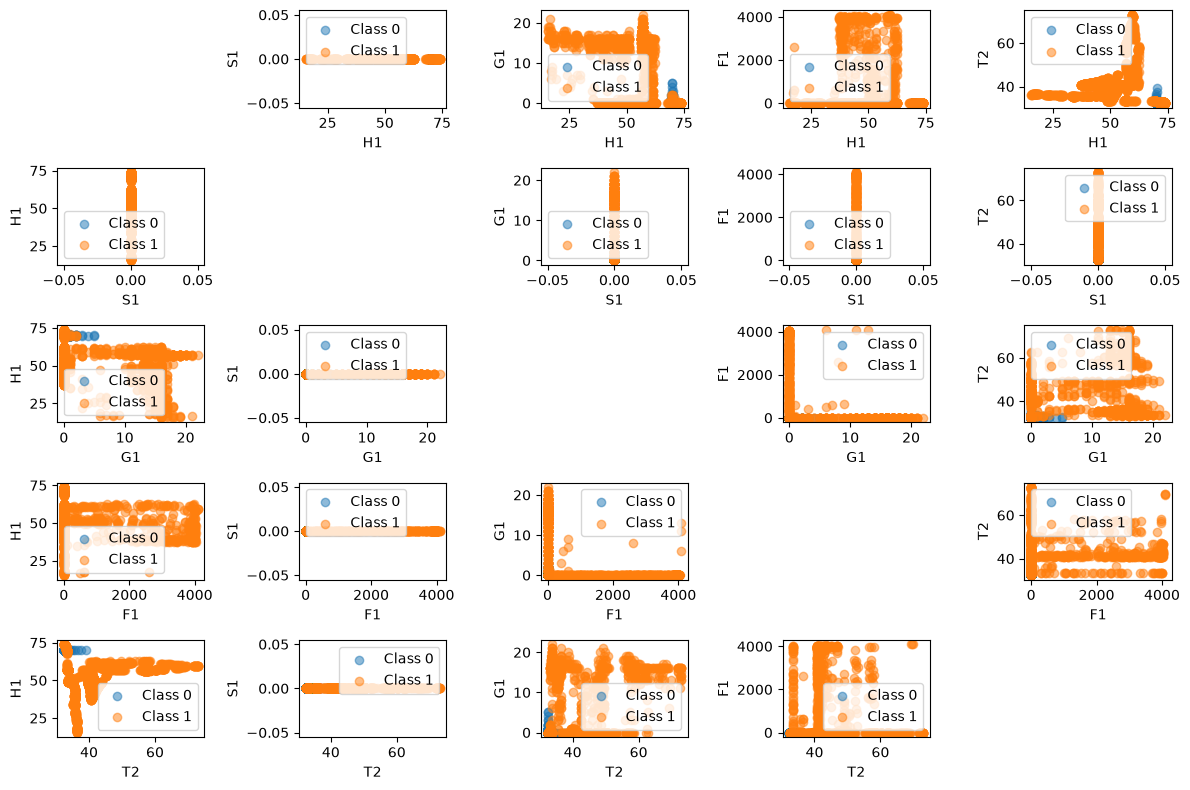

In [4]:
ourdataFrame = pd.DataFrame((data))

#Data visualization

# Assuming you have a DataFrame 'data' with 24 features and a 'target' column containing class labels (0 or 1)
# Replace 'data' and 'target' with your actual data and target columns.

# Combine the features and target into a single DataFrame
data_with_target = ourdataFrame.copy()
target = data_with_target['CLASS_LABEL']

selected_features = data_with_target.columns[1:6]

# Create scatter plots for selected features colored by class labels
plt.figure(figsize=(12, 8))
for i, feature1 in enumerate(selected_features):
    for j, feature2 in enumerate(selected_features):
        if i != j:
            plt.subplot(len(selected_features), len(selected_features), i * len(selected_features) + j + 1)
            for class_label in [0, 1]:  # Assuming binary classification
                plt.scatter(
                    data_with_target[data_with_target['CLASS_LABEL'] == class_label][feature1],
                    data_with_target[data_with_target['CLASS_LABEL'] == class_label][feature2],
                    label=f'Class {class_label}', alpha=0.5
                )
            plt.xlabel(feature1)
            plt.ylabel(feature2)
            plt.legend()
plt.tight_layout()
plt.show()


In [5]:
model = Sequential(
    [
        tf.keras.Input(shape=(X_train.shape[1],)),
        Dense(10, activation='sigmoid', name = 'layer1'), #using 10 neurons in the first layer
        Dense(1, activation='sigmoid', name = 'layer2')
     ]
)

In [6]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ layer1 (Dense)                  │ (None, 10)             │           210 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ layer2 (Dense)                  │ (None, 1)              │            11 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 221 (884.00 B)

 Trainable params: 221 (884.00 B)

 Non-trainable params: 0 (0.00 B)

In [7]:
model.compile(
    loss = tf.keras.losses.BinaryCrossentropy(),
    optimizer = tf.keras.optimizers.Adam(learning_rate=0.01),
)

history = model.fit(
    X_train,y_train,            
    epochs=10,
)

Epoch 1/10
63/63 ━━━━━━━━━━━━━━━━━━━━ 13s 80ms/step - loss: 0.2059
Epoch 2/10
63/63 ━━━━━━━━━━━━━━━━━━━━ 1s 19ms/step - loss: 0.0884
Epoch 3/10
63/63 ━━━━━━━━━━━━━━━━━━━━ 2s 22ms/step - loss: 0.0492
Epoch 4/10
63/63 ━━━━━━━━━━━━━━━━━━━━ 2s 20ms/step - loss: 0.0301
Epoch 5/10
63/63 ━━━━━━━━━━━━━━━━━━━━ 2s 22ms/step - loss: 0.0196
Epoch 6/10
63/63 ━━━━━━━━━━━━━━━━━━━━ 2s 23ms/step - loss: 0.0135
Epoch 7/10
63/63 ━━━━━━━━━━━━━━━━━━━━ 3s 20ms/step - loss: 0.0098
Epoch 8/10
63/63 ━━━━━━━━━━━━━━━━━━━━ 1s 20ms/step - loss: 0.0075
Epoch 9/10
63/63 ━━━━━━━━━━━━━━━━━━━━ 2s 22ms/step - loss: 0.0059
Epoch 10/10
63/63 ━━━━━━━━━━━━━━━━━━━━ 2s 21ms/step - loss: 0.0048


In [8]:
ytest_pred = model.predict(X_test)
ytest_pred_classes = (ytest_pred > 0.5).astype(int)
print(ytest_pred_classes)


16/16 ━━━━━━━━━━━━━━━━━━━━ 1s 43ms/step
[[1]
 [0]
 [0]
 [1]
 [1]
 [1]
 [1]
 [1]
 [1]
 [1]
 [1]
 [1]
 [1]
 [1]
 [1]
 [1]
 [0]
 [1]
 [1]
 [1]
 [1]
 [1]
 [1]
 [1]
 [1]
 [1]
 [1]
 [1]
 [0]
 [1]
 [1]
 [1]
 [0]
 [1]
 [1]
 [1]
 [1]
 [1]
 [1]
 [1]
 [1]
 [1]
 [1]
 [1]
 [1]
 [1]
 [1]
 [1]
 [1]
 [1]
 [0]
 [1]
 [1]
 [1]
 [1]
 [1]
 [1]
 [1]
 [1]
 [1]
 [1]
 [0]
 [1]
 [1]
 [1]
 [1]
 [1]
 [1]
 [1]
 [1]
 [1]
 [1]
 [1]
 [1]
 [1]
 [1]
 [1]
 [1]
 [1]
 [1]
 [1]
 [1]
 [1]
 [1]
 [1]
 [1]
 [1]
 [0]
 [1]
 [1]
 [1]
 [1]
 [1]
 [1]
 [1]
 [1]
 [1]
 [1]
 [0]
 [1]
 [1]
 [1]
 [1]
 [0]
 [0]
 [0]
 [1]
 [1]
 [1]
 [1]
 [1]
 [1]
 [1]
 [1]
 [1]
 [1]
 [1]
 [1]
 [1]
 [1]
 [1]
 [1]
 [1]
 [1]
 [1]
 [1]
 [1]
 [1]
 [1]
 [1]
 [1]
 [1]
 [1]
 [1]
 [1]
 [1]
 [1]
 [1]
 [1]
 [1]
 [1]
 [1]
 [0]
 [0]
 [1]
 [1]
 [1]
 [1]
 [1]
 [1]
 [1]
 [1]
 [1]
 [1]
 [1]
 [0]
 [1]
 [1]
 [1]
 [0]
 [1]
 [0]
 [1]
 [1]
 [1]
 [1]
 [1]
 [1]
 [1]
 [1]
 [0]
 [1]
 [1]
 [0]
 [0]
 [1]
 [1]
 [1]
 [1]
 [1]
 [1]
 [1]
 [1]
 [1]
 [1]
 [1]
 [1]
 [1]
 [1]
 [1]
 [0]
 [1]


In [9]:
# Calculate accuracy using scikit-learn's accuracy_score function
accuracy = accuracy_score(y_test, ytest_pred_classes)

# Print the accuracy
print(f"Accuracy: {accuracy * 100:.2f}%")

#calculate and print f1-score
print(f1_score(y_test, ytest_pred_classes))

Accuracy: 100.00%
1.0


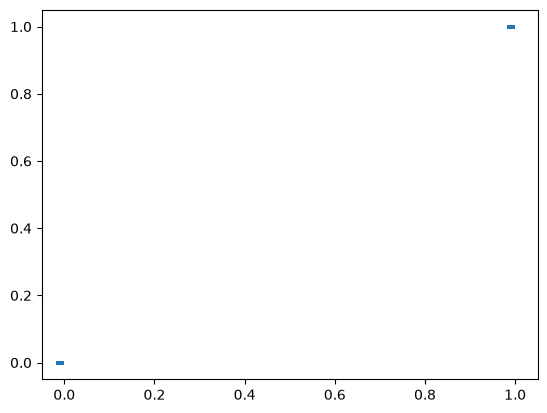

In [10]:
plt.scatter(ytest_pred_classes, y_test, marker=0)

In [11]:
W1, b1 = model.get_layer("layer1").get_weights()
W2, b2 = model.get_layer("layer2").get_weights()
print(f"W1{W1.shape}:\n", W1, f"\nb1{b1.shape}:", b1)
print(f"W2{W2.shape}:\n", W2, f"\nb2{b2.shape}:", b2)

W1(20, 10):
 [[-0.69636095  1.1953552   0.17065468 -0.8165595   0.9388501   0.17340167
   0.9269389  -1.1346399   0.25724855  1.3324946 ]
 [ 0.94463897  0.3318197   0.15030605  0.2731732  -0.6608729  -0.22280322
  -0.464097    0.1859456   0.21882002 -0.6798231 ]
 [ 0.28152275  0.09522849 -0.19718483  0.28006476  0.0897491   0.40658814
  -0.11976555  0.17046219  0.41263723  0.4253984 ]
 [-0.18130867  0.01407475 -0.92470056 -0.239292    0.54303324  0.07565954
   0.05228328  0.02937981 -0.998133    0.01769515]
 [ 0.10976601 -0.2245754  -0.22075593  0.1865609   0.1516858  -0.4097508
  -0.2067211   0.5729938   0.14116271 -0.23940128]
 [-0.3895932   0.4407083   0.59126663 -0.2130021   0.63799375 -0.06028703
   0.6871187  -0.57599044  1.1505003   0.5616261 ]
 [ 0.7049089   0.39825436 -0.20867835 -0.36608544 -0.6939006   0.04697547
  -0.20485687  0.26052016 -0.08634459 -0.84640676]
 [ 0.20953965 -0.08785126 -0.10588044  0.11374259 -0.34566176 -0.17381155
   0.06987852  0.43667346 -0.41348317  

In [12]:
for layer in model.layers[:-1]:
    W, b = layer.get_weights()
    print(layer.name, "weights:", W.shape, "biases:", b.shape)
output_layer = model.layers[-1]
W, b = output_layer.get_weights()
print(output_layer.name, "weights:", W.shape, "biases:", b.shape)

layer1 weights: (20, 10) biases: (10,)
layer2 weights: (10, 1) biases: (1,)


In [13]:

# Convert the model to a quantized version
converter = tf.lite.TFLiteConverter.from_keras_model(model)
converter.optimizations = [tf.lite.Optimize.DEFAULT]
quantized_model = converter.convert()

# Save the quantized model
with open('quantized_model.tflite', 'wb') as f:
    f.write(quantized_model)

# Load and run the quantized model with TensorFlow Lite
interpreter = tf.lite.Interpreter(model_path='quantized_model.tflite')
interpreter.allocate_tensors()

# Get input and output tensors
input_details = interpreter.get_input_details()
output_details = interpreter.get_output_details()

# Test the model with a sample data point from the test set
input_data = X_test[0:1].astype(input_details[0]['dtype'])
interpreter.set_tensor(input_details[0]['index'], input_data)

# Run the interpreter
interpreter.invoke()

# Get the result
output = interpreter.get_tensor(output_details[0]['index'])
print(output)

INFO:tensorflow:Assets written to: C:\Users\user\AppData\Local\Temp\tmpnztqxl4i\assets


INFO:tensorflow:Assets written to: C:\Users\user\AppData\Local\Temp\tmpnztqxl4i\assets


Saved artifact at 'C:\Users\user\AppData\Local\Temp\tmpnztqxl4i'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 20), dtype=tf.float32, name='keras_tensor')
Output Type:
  TensorSpec(shape=(None, 1), dtype=tf.float32, name=None)
Captures:
  2177524483808: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2177524288864: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2177524284976: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2177524284496: TensorSpec(shape=(), dtype=tf.resource, name=None)
[[0.9995867]]


c:\Users\user\anaconda3\Lib\site-packages\tensorflow\lite\python\interpreter.py:468: UserWarning:     Warning: tf.lite.Interpreter is deprecated and is scheduled for deletion in
    TF 2.20. Please use the LiteRT interpreter from the ai_edge_litert package.
    See the [migration guide](https://ai.google.dev/edge/litert/migration)
    for details.
    
  warnings.warn(_INTERPRETER_DELETION_WARNING)


Test examples: 503
Full-precision Keras accuracy: 100.00%
TFLite accuracy: 100.00%
TFLite input dtype: float32
TFLite output dtype: float32
TFLite tensor dtypes: ['float32']


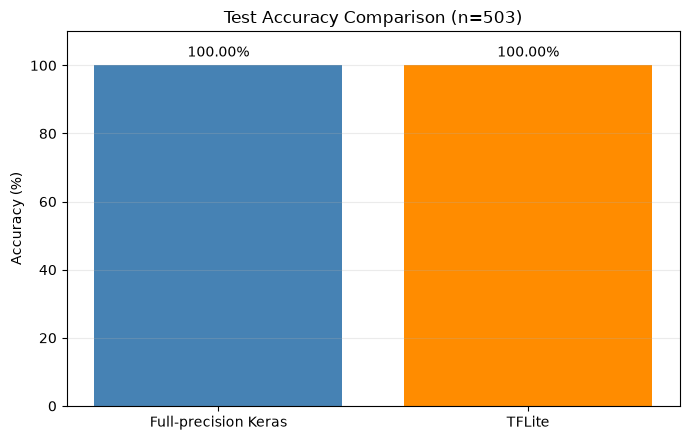

In [14]:
# Compare both models on the complete test set.
y_true = np.asarray(y_test).reshape(-1)

keras_probabilities = np.asarray(model.predict(X_test, verbose=0)).reshape(-1)
keras_predictions = (keras_probabilities > 0.5).astype(int)

input_info = interpreter.get_input_details()[0]
output_info = interpreter.get_output_details()[0]
tflite_probabilities = []
for sample in X_test:
    sample_input = np.asarray(sample[None, :], dtype=input_info["dtype"])
    interpreter.set_tensor(input_info["index"], sample_input)
    interpreter.invoke()
    tflite_probabilities.append(
        interpreter.get_tensor(output_info["index"]).reshape(-1)[0]
    )
tflite_predictions = (np.asarray(tflite_probabilities) > 0.5).astype(int)

keras_accuracy = accuracy_score(y_true, keras_predictions)
tflite_accuracy = accuracy_score(y_true, tflite_predictions)
print(f"Test examples: {len(y_true)}")
print(f"Full-precision Keras accuracy: {keras_accuracy:.2%}")
print(f"TFLite accuracy: {tflite_accuracy:.2%}")
print(f"TFLite input dtype: {np.dtype(input_info['dtype']).name}")
print(f"TFLite output dtype: {np.dtype(output_info['dtype']).name}")
print(
    "TFLite tensor dtypes:",
    sorted({np.dtype(tensor['dtype']).name for tensor in interpreter.get_tensor_details()}),
)

model_names = ["Full-precision Keras", "TFLite"]
accuracies = [keras_accuracy * 100, tflite_accuracy * 100]
fig, ax = plt.subplots(figsize=(7, 4.5))
bars = ax.bar(model_names, accuracies, color=["steelblue", "darkorange"])
ax.set_ylim(0, 110)
ax.set_ylabel("Accuracy (%)")
ax.set_title(f"Test Accuracy Comparison (n={len(y_true)})")
ax.bar_label(bars, fmt="%.2f%%", padding=4)
ax.grid(axis="y", alpha=0.25)
fig.tight_layout()
fig.savefig("model_accuracy_comparison.png", dpi=200, bbox_inches="tight")
plt.show()